In [2]:
# API key prompt for Groq API
import getpass
import os
if "GROQ_API_KEY" not in os.environ:
  os.environ["GROQ_API_KEY"] = getpass.getpass("Enter your Groq API key: ")

In [3]:
# intall the required packages
!pip install langchain-groq langgraph

In [4]:
# import the necessary classes from langchain_groq and langchain_core
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage, AIMessage

In [5]:
# Reasoning Models with Action (ReAct) using LangGraph
# Allow an account-specific Groq model override; this default is available in this project.
model_name = os.getenv("GROQ_MODEL", "openai/gpt-oss-120b")
llm = ChatGroq(
    model=model_name,
    temperature=0,
    max_tokens=None,
    timeout=None,
    max_retries=2
)

In [6]:
# Tool methods for ReAct Add Each tool method should have a docstring that describes the tool's functionality and its arguments. The docstring should be formatted in a way that is compatible with the ReAct framework.
def multiply(a: int, b: int) -> int:
    """Multiply a and b.
        Args:
        a: first int
        b: second int
    """
    return a * b

def add(a: int, b: int) -> int:
    """Adds a and b.
        Args:
        a: first int
        b: second int
    """
    return a + b

def divide(a: int, b: int) -> float:
    """Divide a and b.
        Args:
        a: first int
        b: second int
    """
    return a / b
# List of tools for ReAct
tools = [add, multiply, divide]

In [7]:
# tool call here
llm_with_tools = llm.bind_tools(tools)

In [8]:
from langgraph.graph import MessagesState
from langchain_core.messages import HumanMessage, SystemMessage

# System message
sys_msg = SystemMessage(content="You are a helpful assistant tasked with performing arithmetic on a set of inputs.")

# Node
def assistant(state: MessagesState):
    return {"messages": [llm_with_tools.invoke([sys_msg] + state["messages"])]}

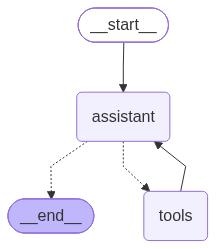

In [9]:
# Create a LangGraph with the assistant node and Edges
from langgraph.graph import START, StateGraph
from langgraph.prebuilt import tools_condition
from langgraph.prebuilt import ToolNode
from IPython.display import Image, display

# Graph
builder = StateGraph(MessagesState)
# Define nodes: these do the work
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))

# Define edges: these determine how the control flow moves
builder.add_edge (START, "assistant")
builder.add_conditional_edges(
    "assistant",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call - tools_condition routes to END
    tools_condition
)

builder.add_edge("tools","assistant") # loop back to assistant after tool call
react_graph = builder.compile()

# Show
display(Image(react_graph.get_graph(xray=True).draw_mermaid_png()))

In [10]:
# check the graph using a test message no memery here
messages = [HumanMessage(content="Add 44 and 22")]
messages = react_graph.invoke({"messages": messages})
for m in messages['messages']:
    m.pretty_print()


================================ Human Message =================================

Add 44 and 22
================================== Ai Message ==================================
Tool Calls:
  add (fc_19026ead-b42d-46de-b16d-cd2208207684)
 Call ID: fc_19026ead-b42d-46de-b16d-cd2208207684
  Args:
    a: 44
    b: 22
================================= Tool Message =================================
Name: add

66
================================== Ai Message ==================================

66


In [11]:
# continue message here show except 66 this is a test for memory no memory here
messages = [HumanMessage(content="Multiply that by 3")]
messages = react_graph.invoke({"messages": messages})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Multiply that by 3
================================== Ai Message ==================================

I’m happy to help with the multiplication, but I need to know the number you’d like to multiply by 3. Could you please provide that value?


In [12]:
# adding Local Databse SQLite
!pip install langgraph-checkpoint-sqlite

In [13]:
# import sqlite3
import sqlite3

In [14]:
# Add github Database table cell window use wget mac curl -> Folder added State_db/example.db file
# !mkdir -p state_db && [ ! -f state_db/example.db ] && wget -P state_db https://github.com/langchain-ai/langchain-academy/raw/main/module-2/state_db/example.db

!mkdir -p state_db && curl -fL https://raw.githubusercontent.com/langchain-ai/langchain-academy/main/module-2/state_db/example.db -o state_db/example.db

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  108k  100  108k    0     0   145k      0 --:--:-- --:--:-- --:--:--  146k


In [15]:
# connect SQLLite DB
db_path = "state_db/example.db"
conn = sqlite3. connect (db_path, check_same_thread=False)
cursor = conn.cursor()

In [16]:
# Check how many tables here in sqlite
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
tables = cursor.fetchall()

print("Tables in the database:")
for table in tables:
    print(table[0])

Tables in the database:
checkpoints
writes


In [17]:
# Fetch first 5 rows
table_name = "checkpoints"
cursor.execute(f"SELECT * FROM {table_name} LIMIT 5;")
rows = cursor.fetchall()
print(f"\nSample data from (table_name):")
for row in rows:
    print (row)


Sample data from (table_name):
('1', '', '1ef64b22-3155-65d8-bfff-cb35a53ab872', None, 'json', b'{"v": 1, "ts": "2024-08-27T20:22:52.733166+00:00", "id": "1ef64b22-3155-65d8-bfff-cb35a53ab872", "channel_values": {"messages": [], "__start__": {"messages": [{"lc": 1, "type": "constructor", "id": ["langchain", "schema", "messages", "HumanMessage"], "kwargs": {"content": "hi! I\'m Lance", "type": "human"}}]}}, "channel_versions": {"__start__": "00000000000000000000000000000001.761a8c54329ca020d4813f3f8164401b"}, "versions_seen": {"__input__": {}}, "pending_sends": [], "current_tasks": {}}', b'{"source": "input", "writes": {"messages": [{"lc": 1, "type": "constructor", "id": ["langchain", "schema", "messages", "HumanMessage"], "kwargs": {"content": "hi! I\'m Lance", "type": "human"}}]}, "step": -1}')
('1', '', '1ef64b22-315d-6eae-8000-a235a23be95b', '1ef64b22-3155-65d8-bfff-cb35a53ab872', 'json', b'{"v": 1, "ts": "2024-08-27T20:22:52.736675+00:00", "id": "1ef64b22-315d-6eae-8000-a235a23be9

In [19]:
# connect Sqlite Memory saver
from langgraph.checkpoint.sqlite import SqliteSaver

In [21]:
# SQLite add memory saver
memory = SqliteSaver (conn)

# connect Data base
graph = builder.compile(checkpointer=memory)

In [24]:
config = {"configurable": {"thread_id": "1"}}

input_message = HumanMessage(content="hi! I'm KamalM")
output = graph.invoke({"messages": [input_message]}, config)
for m in output['messages'][-1:]:
    m.pretty_print()

input_message = HumanMessage(content="what's my name?")
output = graph.invoke({"messages": [input_message]}, config)
for m in output['messages'][-1:]:
    m.pretty_print()

input_message = HumanMessage(content="i like the 36ers!")
output = graph.invoke({"messages": [input_message]}, config)
for m in output['messages'][-1:]:
    m.pretty_print()

================================== Ai Message ==================================

Nice to meet you, KamalM! How can I help you today?
================================== Ai Message ==================================

Your name is KamalM.
================================== Ai Message ==================================

That’s great! The Adelaide 36ers have a passionate fan base and a rich history in the NBL. Do you have a favorite player, season, or memorable game you’d like to talk about?


In [26]:
# view all messages
config = {"configurable": {"thread_id": "1"}}
graph_state = graph.get_state(config)
graph_state

StateSnapshot(values={'messages': [HumanMessage(content="hi! I'm Lance", additional_kwargs={}, response_metadata={}, id='086e80ce-8bd0-4dee-b13c-f47160d6755f'), AIMessage(content="Hello Lance! You've already introduced yourself, but it's nice to greet you again. Is there something specific you'd like to talk about? Perhaps you'd like to continue our conversation about the 49ers, or is there another topic you're interested in discussing?", additional_kwargs={}, response_metadata={'id': 'msg_01AkDF6AH7LMp2YDDD9jQkEC', 'model': 'claude-3-5-sonnet-20240620', 'stop_reason': 'end_turn', 'stop_sequence': None, 'usage': {'input_tokens': 197, 'output_tokens': 58}}, id='run-7f8af5e1-5248-4ccd-ab46-87580422f0d6-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 197, 'output_tokens': 58, 'total_tokens': 255}), HumanMessage(content="what's my name?", additional_kwargs={}, response_metadata={}, id='e33f42ee-cdb0-45ec-b100-54dcd4c82e71'), AIMessage(content="Your name is Lance. 